# MLP Model (PyTorch)

The following demos building a Multi-Layer Perceptron (MLP) model. The arguments used to build the model mirrors those found wiht the graph models.

## Import Modules

In [1]:
from mminer_graphs.model import MLP, EarlyStopping, summary
from mminer_graphs.plot import Plots
import pandas as pd
import datamol as dm

## Dataset Prep
The sample dataset is taken from [MoleculeNet](https://moleculenet.org) and uses their BACE dataset. This dataset includes quantitative (IC50) and qualitative (binary labels) binding results for inhibitors of human beta secretase (BACE-1). The only modification the dataset was replacing their default split with a random split and including cross-validation columns with random splits.

In this case, a model will be created using a single split (Model). After extracting the necessary information, the Data will contain the following format:

In [2]:
data = pd.read_csv("../dataset/bace.csv")
cols = ['CID', 'smiles', 'Class', 'Model']
dataset = data[cols]
print(f"The shape of the dataset: {dataset.shape}")
dataset.head()

The shape of the dataset: (1513, 4)


,CID,smiles,Class,Model
0,BACE_1,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,1,train
1,BACE_2,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,1,train
2,BACE_3,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train
3,BACE_4,S1(=O)(=O)C[C@@H](Cc2cc(O[C@H](COCC)C(F)(F)F)c...,1,train
4,BACE_5,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train


## Molecular Fingerprint

The molecules will now be featureized. There are many different ways to featurize molecules. Here, a molecular fingerprint will be generated for each molecule using [Datamol](https://github.com/datamol-io/datamol). The fingerprints will be placed into a list.

In [3]:
train = dataset[dataset.iloc[:, -1] == 'train'].copy()
test = dataset[dataset.iloc[:, -1] == 'test'].copy()

train_mols = dm.from_df(train, smiles_column="smiles")
test_mols = dm.from_df(test, smiles_column="smiles")

In [4]:
fp_list_train = []
train_labels = []
fp_list_test = []
test_labels = []
for x, label in zip(train_mols, train.Class):
    fp = dm.to_fp(x)
    fp_list_train.append(fp)
    train_labels.append(label)
for x, label in zip(test_mols, test.Class):
    fp = dm.to_fp(x)
    fp_list_test.append(fp)
    test_labels.append(label)

### Optional

The fingerprints can be appended to the input Dataframe. This can make it easier to save the file in a .csv format for sharing or for future parsing.

In [5]:
fp_df = pd.DataFrame(fp_list_train, index=train.index)
fp_df.columns = [f"fp_{i}" for i in range(fp_df.shape[1])]
train = pd.concat([train, fp_df], axis=1)
train.head()

,CID,smiles,Class,Model,fp_0,fp_1,fp_2,fp_3,fp_4,fp_5,...,fp_2038,fp_2039,fp_2040,fp_2041,fp_2042,fp_2043,fp_2044,fp_2045,fp_2046,fp_2047
0,BACE_1,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,1,train,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,BACE_2,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,1,train,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2,BACE_3,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train,1,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,BACE_4,S1(=O)(=O)C[C@@H](Cc2cc(O[C@H](COCC)C(F)(F)F)c...,1,train,0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,BACE_5,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Train the Model

To train the model, the MLP class must be instantiated. There are several parameters that are needed, such as input size and the number of layers.

In this example, the 2048 fp bits are used as the input size and the hidden_size is set to 64. The model will be setup with three layers. Finally, the **reduce_size** argument will be set to False. If set to True, each subsequent layer nodes will be halved. This example will keep the nodes constant.

In [6]:
model = MLP(input_size=2048, hidden_size=64, layers=3, reduce_size=True)
summary(model, x=2048)

Layer (type:depth-idx)                   Output Shape              Param #
MLP                                      [1, 2]                    --
├─ModuleList: 1-1                        --                        --
│    └─Sequential: 2-1                   [1, 64]                   --
│    │    └─Linear: 3-1                  [1, 64]                   131,136
│    │    └─BatchNorm1d: 3-2             [1, 64]                   128
│    │    └─ReLU: 3-3                    [1, 64]                   --
│    │    └─Dropout: 3-4                 [1, 64]                   --
│    └─Sequential: 2-2                   [1, 32]                   --
│    │    └─Linear: 3-5                  [1, 32]                   2,080
│    │    └─BatchNorm1d: 3-6             [1, 32]                   64
│    │    └─ReLU: 3-7                    [1, 32]                   --
│    │    └─Dropout: 3-8                 [1, 32]                   --
│    └─Linear: 2-3                       [1, 2]                    66
Total 

A summary of the model can be printed. This is wrapped from [torchinfo](https://github.com/TylerYep/torchinfo) and follows its basic usage.

**EarlyStopping** can also be used. Here it will be called to monitor the validation/test data.

In this tutorial, the **EarlyStopping** class is instantiated, but the patience is set at 5. It is only used here to give an example of how to use it. The patience can be set accordingly.

In [7]:
estop = EarlyStopping(monitor='val_loss', patience=5, mode='min')

### Fit the Model

The model can be fit in a similar fashion as the sklearn api by calling the **.fit()** instance method. There are several mandatory parameters needed to ensure that the model is fitted:
- The model train, test, train_labels, and test_labels.

All other arguments are optional or given by default.

In this model, the model will be trained on cpu and early stopping will be given as set in the cell above. Epochs will be set to 10.

In [8]:
model.fit(x_train=fp_list_train, y_train=train_labels, x_test=fp_list_test, y_test=test_labels, epochs=10, device="cpu", estop=estop)

Model and Tensor running on cpu


Epoch: 100%|██████████| 10/10 [00:00<00:00, 70.97it/s]

Best Training Loss: 0.083
Best Test Loss: 0.455
Best Training Accuracy: 0.971
Best Test Accuracy: 0.832


## Plots

The mol-miner-graphs comes with basic plot functions. This section will demo their usage.

### Curves
The **curves()** method will generate the loss curve and accuracy curves for the model. It will use the results from the Test data. The figure here is drawn with default settings, however the **curves()** method contains additional parameters, such as line colors, figsize, or other metrics to plot (Precision).

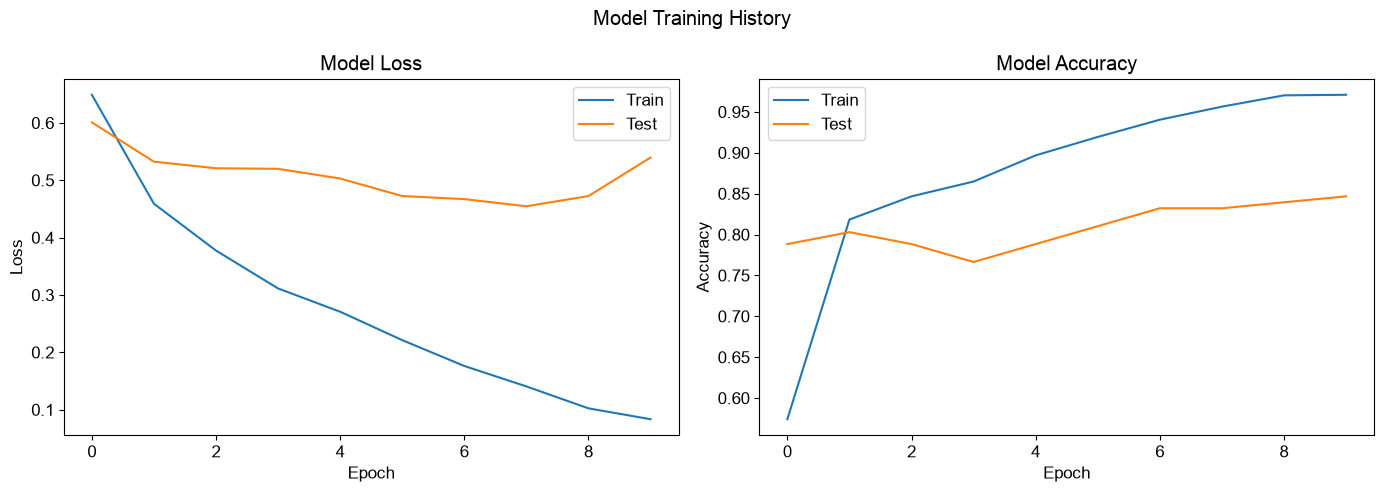

In [9]:
plot = Plots(model, x_data=fp_list_test, y_data=test_labels, device='cpu', batch_size=1024)
plot.curves()

### Confusion Matrix

A confusion matrix can be drawn using the **confusion_matrix()** method. The class names will default to 0 and 1. Here, they are renamed as "Inactive" and "Active" using the **class_names** parameter. The device is an important parameter and should be modified to use the same as the model fitting. For example, if the model was fitted using 'cpu', then the confusion matrix device should be set to 'cpu'. Additional parameters are available to modify the title, figsize, and cmap.

Prediction running on cpu


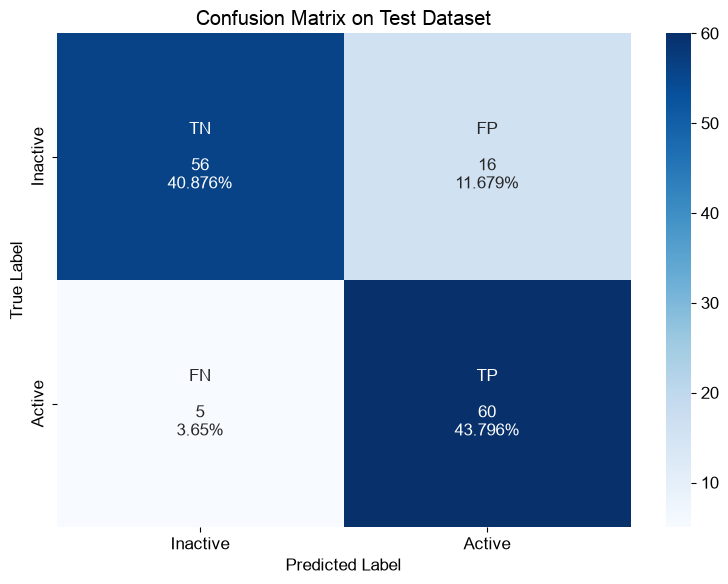

In [10]:
plot.confusion_matrix(class_names=['Inactive', 'Active'])

### Classification Report
A classification report can also be generated. The parameters are similar to the **confusion_matrix()** method.

Prediction running on cpu


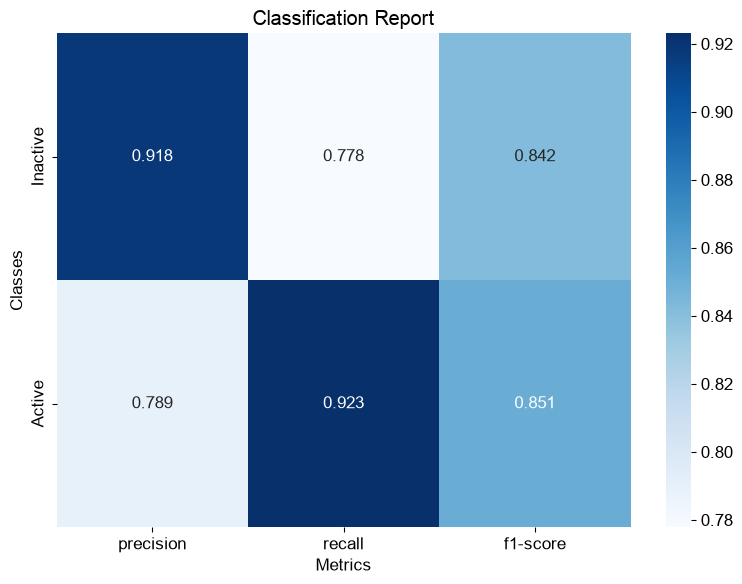

In [11]:
plot.classification_report(class_names=['Inactive', 'Active'])

An **[roc_curve()](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html)** can be drawn and displays the classifier output quality.

Prediction running on cpu


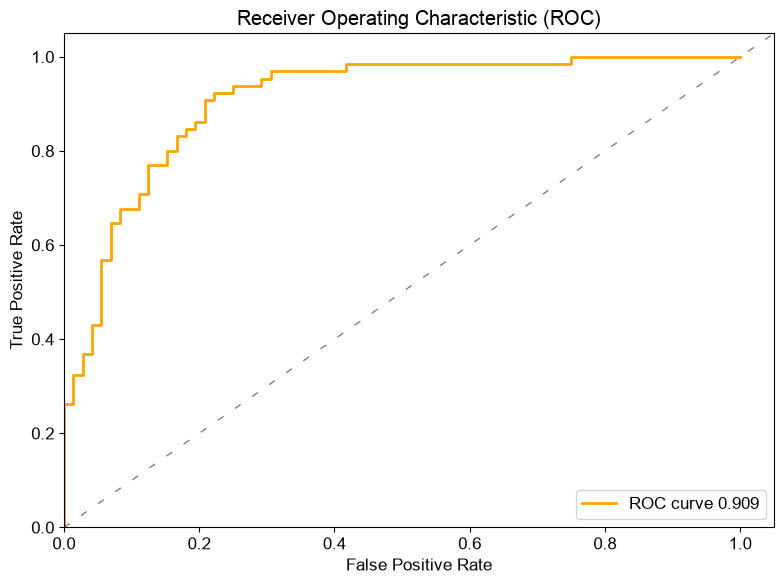

In [12]:
plot.roc_curve(model)

The **[pr_curve()](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html)** can be drawn to show the tradeoff between precision and recall for different thresholds.

Prediction running on cpu


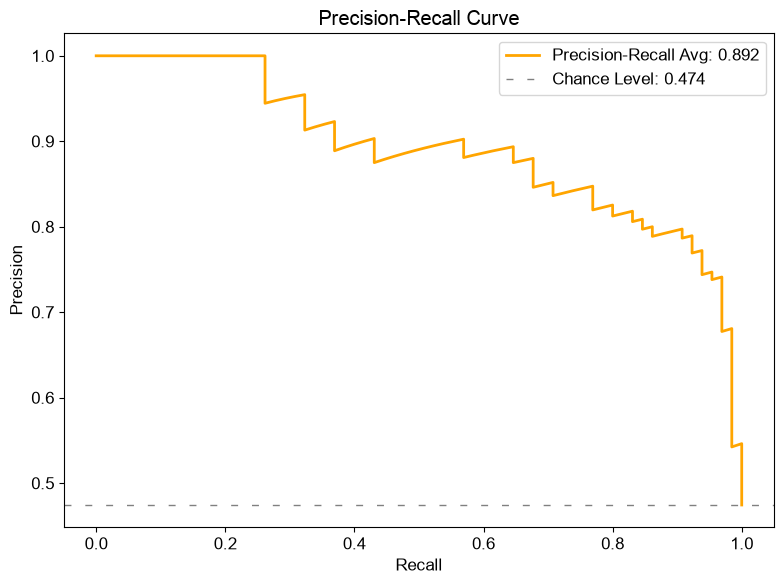

In [13]:
plot.pr_curve(model=model, chance_level=True)

## Making Predictions

Additionally, the mol-miner-graphs package contains a **.predict()** for easier usability. This will output a list of results on a tensor. By default, the **.predict()** method  it will output results as a list for easier use with pd.DataFrames. In this example, the results are given as a tensor. Users that wish to append this to a pd.DataFrame will need to convert the results using **.tolist()**

In [14]:
model.predict(data=fp_list_test, device="cpu", return_type="tensor", binary=True)

Prediction running on cpu


tensor([1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
        0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0], dtype=torch.int32)

## Saving and Loading a Model
After fitting a model, they can be saved and loaded using the **.save()** or **.load()** instance variables. For PyTorch models, the saved model must have the *.pth* extension.

In [15]:
model.save("test.pth")

'Model saved!'

To load a molecule, a model must be initialized using the same param as was used for saved model. For this example, teh same GCNNet used above was pasted to reset the model variable.

In [16]:
model = MLP(input_size=2048, hidden_size=64, layers=3)
model.load("test.pth", device="cpu")
print(summary(model, x=fp_list_train))

Model loaded!
Layer (type:depth-idx)                   Output Shape              Param #
MLP                                      [1, 2]                    --
├─ModuleList: 1-1                        --                        --
│    └─Sequential: 2-1                   [1, 64]                   --
│    │    └─Linear: 3-1                  [1, 64]                   131,136
│    │    └─BatchNorm1d: 3-2             [1, 64]                   128
│    │    └─ReLU: 3-3                    [1, 64]                   --
│    │    └─Dropout: 3-4                 [1, 64]                   --
│    └─Sequential: 2-2                   [1, 32]                   --
│    │    └─Linear: 3-5                  [1, 32]                   2,080
│    │    └─BatchNorm1d: 3-6             [1, 32]                   64
│    │    └─ReLU: 3-7                    [1, 32]                   --
│    │    └─Dropout: 3-8                 [1, 32]                   --
│    └─Linear: 2-3                       [1, 2]               

# Regression

Regression models are built similarly to Classification models demoed above. The main parameter changes are with the criterion and the num_classes.

## Dataset Prep
The dataset for this example will use the same as above, with the dataset taken form [MoleculeNet](https://moleculenet.org) and uses their BACE dataset. Instead of qualitative binding (binary labels) , the demo will utilize the quantitative (pIC50) labels for inhibitors of human beta secretase (BACE-1).

The dataset will be prepared as follows:

In [17]:
data = pd.read_csv("dataset/bace.csv")
cols = ['CID', 'smiles', 'pIC50', 'Model']
dataset = data[cols]
print(f"The shape of the dataset: {dataset.shape}")
dataset.head()

FileNotFoundError: [Errno 2] No such file or directory: 'dataset/bace.csv'

In [ ]:
train = dataset[dataset.iloc[:, -1] == 'train'].copy()
test = dataset[dataset.iloc[:, -1] == 'test'].copy()

train_mols = dm.from_df(train, smiles_column="smiles")
test_mols = dm.from_df(test, smiles_column="smiles")

In [ ]:
fp_train = []
train_labels = []
fp_test = []
test_labels = []
for x, label in zip(train_mols, train.pIC50):
    fp = dm.to_fp(x)
    fp_train.append(fp)
    train_labels.append(label)
for x, label in zip(test_mols, test.pIC50):
    fp = dm.to_fp(x)
    fp_test.append(fp)
    test_labels.append(label)

## Training the Model
Training the model will work similarly to the Classification model above. Note that for Regression models, the num_classes is set to 1.

In [ ]:
model = MLP(input_size=2048, hidden_size=64, layers=3, reduce_size=True, num_classes=1)
model

### Fitting the Model

For regression models, the criterion will need to be changed. All other parameters should be similar to what was used for Classification models.

In [ ]:
model.fit(x_train=fp_train, y_train=train_labels, x_test=fp_list_test, y_test=test_labels, epochs=10, device="cpu", estop=estop, criterion='mse')

## Plot

### Curves
The **curves()** method will generate the loss curve and the associated Regression metric. What is plotted can be given as a list.

In [ ]:
plot = Plots(model, x_data=fp_test, y_data=test_labels, device='cpu')
plot.curves(metrics=['loss', 'mae'])

For Regression models, a regression plot can be drawn.

In [ ]:
plot.regression()